<a href="https://colab.research.google.com/github/AsmaaaSalis/agriprice-teller-intelligence/blob/main/01_data_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AgriPrice Intelligence: Agricultural Price Forecasting for Nigeria

## Project overview
Farmers and traders in Nigeria often lack reliable information on how food prices
move, which makes it hard to decide when and where to sell. This project uses public
WFP food price data to study price patterns and test how well future prices can be
forecast, using simple baselines, statistical models and machine learning.
The audit in this notebook starts from the national data and then narrows the project
to the regions and commodities the data can support.

Notebooks in this project:
1. Data audit (this notebook)
2. Data preparation
3. Exploratory data analysis
4. Forecasting
5. Market intelligence outputs

## Notebook 1: Data Audit
Checking what the WFP Nigeria food price data can support before any modelling:
date range, which states and markets report, and how many months are missing.
The results decide the project's scope (which region and commodities).

Data: WFP Nigeria food prices (wfp_food_prices_nga.csv, data to October 2026).

In [1]:
# Importing libraries

import pandas as pd              # Data tables
import numpy as np               # Missing values and maths
import re                        # Reading units, e.g. "2.5 KG"
import matplotlib.pyplot as plt  # Charts

# Setting display options
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 100)

print('Libraries loaded')

Libraries loaded


### 1. Loading the data
Confirming the file loads and matches its description.

In [2]:
# Loading the WFP Nigeria food prices data (updated file)
df = pd.read_csv('wfp_food_prices_nga.csv', parse_dates=['date'])

# Keeping data up to October 2026 (November 2026 is only partly reported)
df = df[df['date'] <= '2026-10-31'].copy()

# Checking the size of the table (rows, columns)
print(df.shape)

# Viewing the first 5 rows
df.head()

(90849, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Maize,51,KG,actual,Wholesale,NGN,175.92,1.54
1,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Millet,73,KG,actual,Wholesale,NGN,150.18,1.31
2,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Rice (imported),64,KG,actual,Wholesale,NGN,358.70,3.14
3,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,cereals and tubers,Sorghum,65,KG,actual,Wholesale,NGN,155.61,1.36
4,2002-01-15,Katsina,Jibia,Jibia (CBM),1038,13.08,7.24,pulses and nuts,Beans (niebe),120,KG,actual,Wholesale,NGN,196.87,1.72


### 2. Missing values and column types
Checking for empty cells and that `date` is read as a real date.

In [3]:
# Counting missing values in each column
print(df.isnull().sum())

# Checking the data type of each column
print(df.dtypes)

date            0
admin1          0
admin2          0
market          0
market_id       0
latitude        0
longitude       0
category        0
commodity       0
commodity_id    0
unit            0
priceflag       0
pricetype       0
currency        0
price           0
usdprice        0
dtype: int64
date            datetime64[ns]
admin1                  object
admin2                  object
market                  object
market_id                int64
latitude               float64
longitude              float64
category                object
commodity               object
commodity_id             int64
unit                    object
priceflag               object
pricetype               object
currency                object
price                  float64
usdprice               float64
dtype: object


### 3. Date range and records per year
Shows how far back the data goes and when coverage becomes consistent.

In [4]:
# Checking the date range
print(df['date'].min(), 'to', df['date'].max())

# Counting records per year
print(df.groupby(df['date'].dt.year).size())

2002-01-15 00:00:00 to 2026-10-15 00:00:00
date
2002      124
2003      176
2004       36
2005      192
2006       91
2007       76
2008      219
2009      196
2010      275
2011      273
2012      328
2013      414
2014     1475
2015     3117
2016     4423
2017     7544
2018     8261
2019     9417
2020     9950
2021    10453
2022     7648
2023     6097
2024     6049
2025     8163
2026     5852
dtype: int64


### 4. Retail vs wholesale
The project forecasts retail prices, so we check when retail records become consistent.

In [5]:
# Counting records per year, split by price type (Retail vs Wholesale)
print(pd.crosstab(df['date'].dt.year, df['pricetype']))

pricetype  Retail  Wholesale
date                        
2002            0        124
2003            0        176
2004            0         36
2005            0        192
2006            0         91
2007            0         76
2008            0        219
2009            0        196
2010            0        275
2011            0        273
2012            0        328
2013            0        414
2014          286       1189
2015          700       2417
2016         1909       2514
2017         5329       2215
2018         6437       1824
2019         7594       1823
2020         7774       2176
2021         8104       2349
2022         5271       2377
2023         5899        198
2024         6049          0
2025         8163          0
2026         5852          0


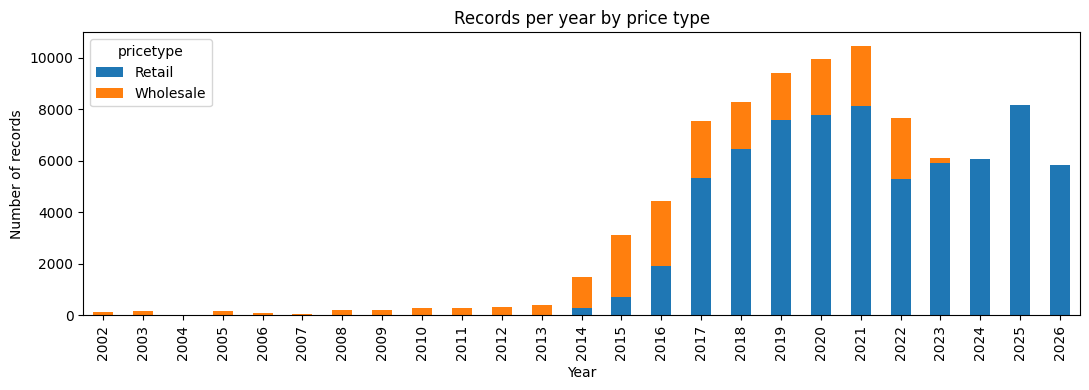

In [6]:
# Plotting records per year, stacked by price type
counts = pd.crosstab(df['date'].dt.year, df['pricetype'])
counts.plot(kind='bar', stacked=True, figsize=(11, 4))
plt.title('Records per year by price type')
plt.xlabel('Year')
plt.ylabel('Number of records')
plt.tight_layout()
plt.show()

### 5. Which states report retail prices?
A forecast only covers places that have data.

In [7]:
# Keeping retail records from 2016 onwards
retail = df[(df['pricetype'] == 'Retail') & (df['date'] >= '2016-01-01')]

# Counting records and number of markets per state
print(retail.groupby('admin1').agg(records=('price', 'size'),
                                   markets=('market_id', 'nunique'))
      .sort_values('records', ascending=False))

         records  markets
admin1                   
Borno      29727       28
Yobe       27564       18
Kaduna      1709        2
Adamawa     1659        7
Oyo          969        1
Kebbi        942        1
Gombe        938        1
Zamfara      896        1
Katsina      889        2
Kano         880        1
Lagos        851        1
Jigawa       845        1
Abia         509        1
Sokoto         3        1


In [8]:
# Counting states and markets in the full data
print('All data     -> states:', df['admin1'].nunique(), '| markets:', df['market_id'].nunique())

# Counting states and markets in retail records from 2016
print('Retail 2016+ -> states:', retail['admin1'].nunique(), '| markets:', retail['market_id'].nunique())

All data     -> states: 14 | markets: 68
Retail 2016+ -> states: 14 | markets: 66


In [9]:
# Calculating each state's share of retail records (%)
share = (retail['admin1'].value_counts(normalize=True) * 100).round(1)
print(share)

admin1
Borno      43.5
Yobe       40.3
Kaduna      2.5
Adamawa     2.4
Oyo         1.4
Kebbi       1.4
Gombe       1.4
Zamfara     1.3
Katsina     1.3
Kano        1.3
Lagos       1.2
Jigawa      1.2
Abia        0.7
Sokoto      0.0
Name: proportion, dtype: float64


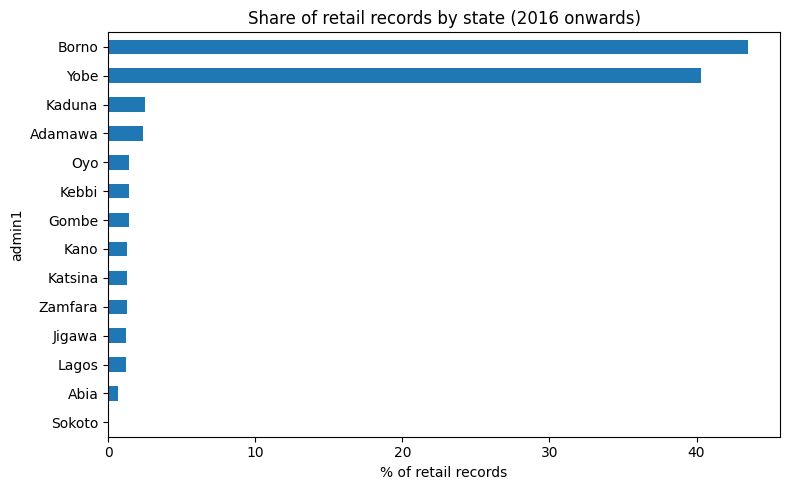

In [10]:
# Plotting each state's share of retail records
share.sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('Share of retail records by state (2016 onwards)')
plt.xlabel('% of retail records')
plt.tight_layout()
plt.show()

In [11]:
# Checking which states report anything after the 2023 policy changes (July 2023 onwards)
post = df[df['date'] >= '2023-07-01']
print('Price types:', post['pricetype'].unique().tolist())
print('States:', sorted(post['admin1'].unique()))

Price types: ['Retail']
States: ['Adamawa', 'Borno', 'Yobe']


### 6. Choosing commodities
Crops farmed in the north with enough price history.

In [12]:
# Keeping retail records for Borno and Yobe only
ne = retail[retail['admin1'].isin(['Borno', 'Yobe'])]

# Viewing the top 15 commodities by number of records
print(ne['commodity'].value_counts().head(15))

commodity
Oil (palm)         2437
Yam                2395
Rice (local)       2380
Millet             2328
Groundnuts         2227
Oil (vegetable)    2226
Onions             2224
Beans (red)        2218
Beans (white)      2216
Fish               2202
Milk (powder)      2198
Eggs               2188
Meat (beef)        2184
Meat (goat)        2177
Maize flour        2175
Name: count, dtype: int64


In [13]:
# Choosing candidate commodities (three picks plus two backups)
candidates = ['Millet', 'Rice (local)', 'Groundnuts', 'Yam', 'Beans (white)']

# Keeping candidate records and adding a month column
cand = ne[ne['commodity'].isin(candidates)].copy()
cand['month'] = cand['date'].dt.to_period('M')

# Counting distinct months with data, per commodity and state
months_with_data = cand.groupby(['commodity', 'admin1'])['month'].nunique().unstack()

# Total months possible between Jan 2016 and Oct 2026
total_months = len(pd.period_range('2016-01', '2026-10', freq='M'))
print('Total months possible:', total_months)
print(months_with_data)

Total months possible: 130
admin1         Borno  Yobe
commodity                 
Beans (white)    117   106
Groundnuts       117   106
Millet           123   117
Rice (local)     125   117
Yam              126   123


In [14]:
# Converting month counts to % of the possible months
coverage_pct = (months_with_data / total_months * 100).round(0)
print(coverage_pct)

admin1         Borno  Yobe
commodity                 
Beans (white)   90.0  82.0
Groundnuts      90.0  82.0
Millet          95.0  90.0
Rice (local)    96.0  90.0
Yam             97.0  95.0


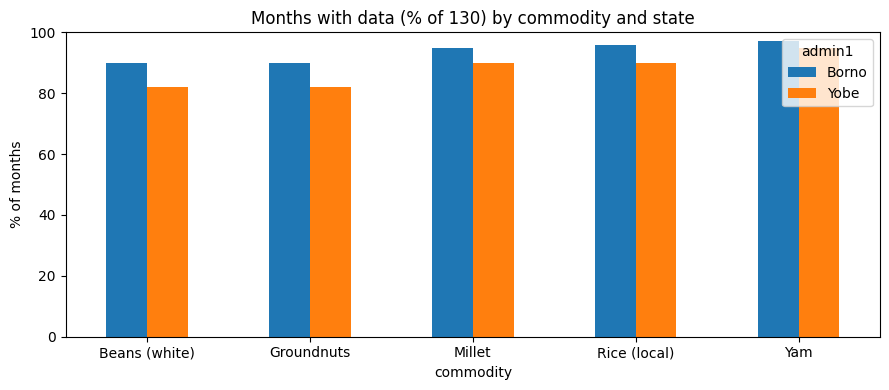

In [15]:
# Plotting % of months with data, per commodity and state
coverage_pct.plot(kind='bar', figsize=(9, 4))
plt.title('Months with data (% of 130) by commodity and state')
plt.ylabel('% of months')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 7. Locking the scope and checking units
Prices come in baskets of different weights, so each crop needs a single consistent unit.

In [16]:
# Saving the project scope
states = ['Borno', 'Yobe']
commodities = ['Millet', 'Rice (local)', 'Groundnuts']

# Keeping retail records for the chosen states and commodities
scope = retail[retail['admin1'].isin(states) & retail['commodity'].isin(commodities)].copy()

# Checking how many records each commodity has in each unit
print(scope.groupby(['commodity', 'unit']).size())

commodity     unit  
Groundnuts    2.2 KG    2227
Millet        2.6 KG    2328
Rice (local)  2.7 KG    2380
dtype: int64


## Audit conclusions

- Data: WFP Nigeria food prices, 90,849 records from January 2002 to October 2026 (November 2026 excluded as only partly reported), no empty cells.
- Records are thin before 2014. Retail prices start in 2014 and are small until 2016 (700 retail vs 2,417 wholesale records in 2015). Retail overtakes wholesale in 2017 (5,329 vs 2,215). Wholesale records end in 2023 (198 records) and are absent from 2024.
- From 2016, retail records cover 14 states and 66 markets, but come mostly from Borno (43.5%) and Yobe (40.3%), together 83.8%; no other state exceeds 2.5%. The project is therefore not Nigeria-wide.
- Since July 2023, the data contains only retail prices, and only for Adamawa, Borno and Yobe.
- Scope: retail prices from January 2016, Borno and Yobe, for millet, rice (local) and groundnuts. These crops are staples farmed in the north, with prices in 82% to 96% of the 130 months (groundnuts 90% Borno / 82% Yobe; millet 95% / 90%; rice 96% / 90%).
- Each chosen crop is reported in a single unit (groundnuts 2.2 KG, millet 2.6 KG, rice 2.7 KG), so prices can be converted to NGN per kg.
- Note: an earlier snapshot of this dataset (54,883 records to November 2025) was incomplete. The updated file contains it plus about 30,000 further records and 2026 data. The audit conclusions are the same on both files.